
TC3: Convergence Test
Number of Iterations: 7
Centroids:
[[5.88360656 2.74098361 4.38852459 1.43442623]
 [5.006      3.428      1.462      0.246     ]
 [6.85384615 3.07692308 5.71538462 2.05384615]]
Original Records : 150
Records After Adding Duplicates : 300


Text(0.5, 1.0, 'TC5: Many Duplicate Points')

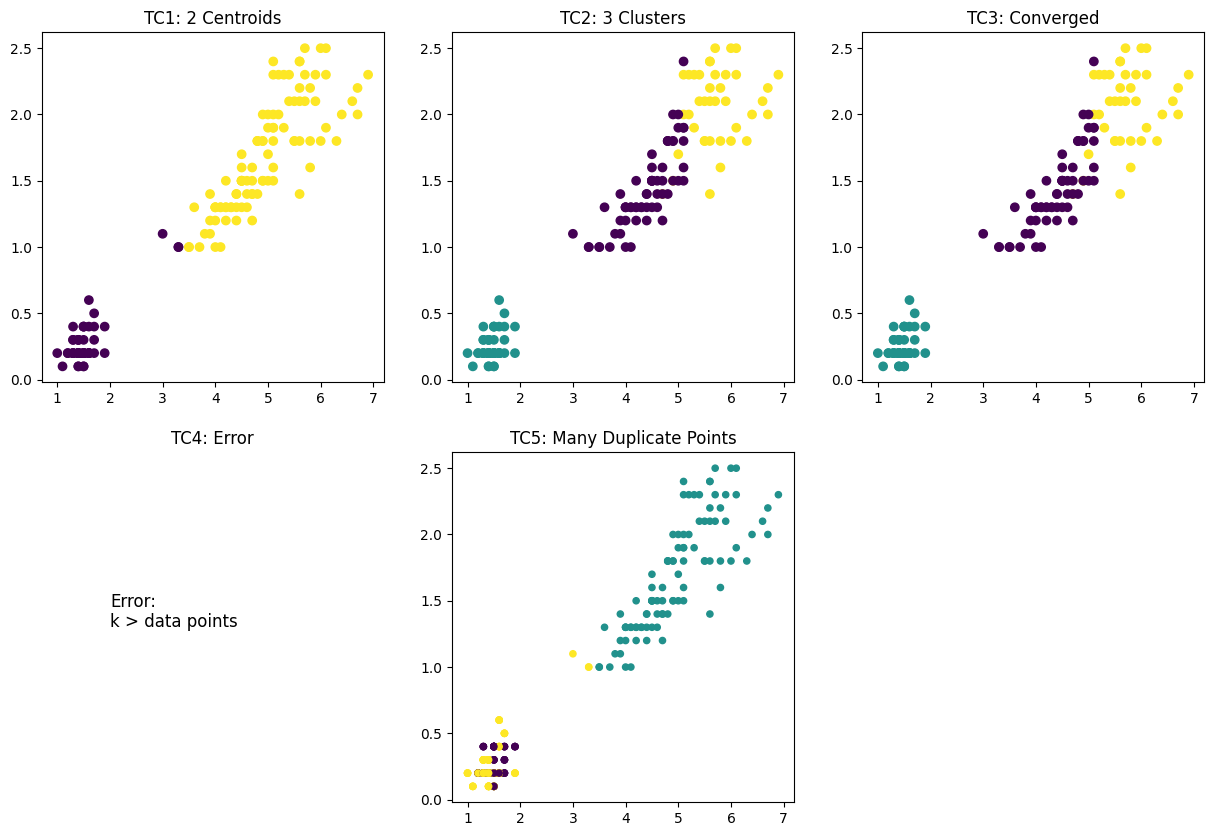

In [ ]:
from sklearn import datasets
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Load Iris Dataset
iris = datasets.load_iris()

X = pd.DataFrame(iris.data)
X.columns = ['Sepal_Length','Sepal_Width',
             'Petal_Length','Petal_Width']

plt.figure(figsize=(15,10))

# ----------------------------------
# TC1: Two Clusters
# ----------------------------------
model1 = KMeans(n_clusters=2, random_state=0)
model1.fit(X)

plt.subplot(2,3,1)
plt.scatter(X['Petal_Length'],
            X['Petal_Width'],
            c=model1.labels_)
plt.title("TC1: 2 Centroids")

# ----------------------------------
# TC2: Three Clusters (Original)
# ----------------------------------
model2 = KMeans(n_clusters=3, random_state=0)
model2.fit(X)

plt.subplot(2,3,2)
plt.scatter(X['Petal_Length'],
            X['Petal_Width'],
            c=model2.labels_)
plt.title("TC2: 3 Clusters")

# ----------------------------------
# TC3: Centroid Convergence
# ----------------------------------

model3 = KMeans(
    n_clusters=3,
    max_iter=300,
    random_state=0
)

model3.fit(X)

plt.subplot(2,3,3)
plt.scatter(X['Petal_Length'],
            X['Petal_Width'],
            c=model3.labels_)
plt.title("TC3: Converged")

print("\nTC3: Convergence Test")
print("Number of Iterations:", model3.n_iter_)
print("Centroids:")
print(model3.cluster_centers_)

# ----------------------------------
# TC4: k > Data Points
# ----------------------------------
plt.subplot(2,3,4)

try:
    X_small = X.head(5)

    model4 = KMeans(n_clusters=10,
                    random_state=0)

    model4.fit(X_small)

except ValueError:
    plt.text(0.2,0.5,
             "Error:\nk > data points",
             fontsize=12)
    plt.axis('off')
    plt.title("TC4: Error")

# ----------------------------------
# TC5: Duplicate Points
# ----------------------------------

# Add first 50 rows three more times
X_dup = pd.concat(
    [X, X.iloc[:50], X.iloc[:50], X.iloc[:50]],
    ignore_index=True
)

print("Original Records :", len(X))
print("Records After Adding Duplicates :", len(X_dup))

model5 = KMeans(n_clusters=3, random_state=0)
model5.fit(X_dup)

plt.subplot(2,3,5)
plt.scatter(X_dup['Petal_Length'],
            X_dup['Petal_Width'],
            c=model5.labels_,
            s=20)

plt.title("TC5: Many Duplicate Points")